# Import the data

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.optimize import differential_evolution
import h5py

In [2]:
hf = h5py.File('../Shared/gammaray_lab4.h5', 'r')

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

In [4]:
data = np.array(hf.get('data'))

In [5]:
print(np.shape(data))
print(data[:,0])

(4, 25920001)
[9.40680016e+08 3.15000000e+02 4.50000000e+01 1.00000000e+01]


In [6]:
hf.close()

# Problem
## Section 1

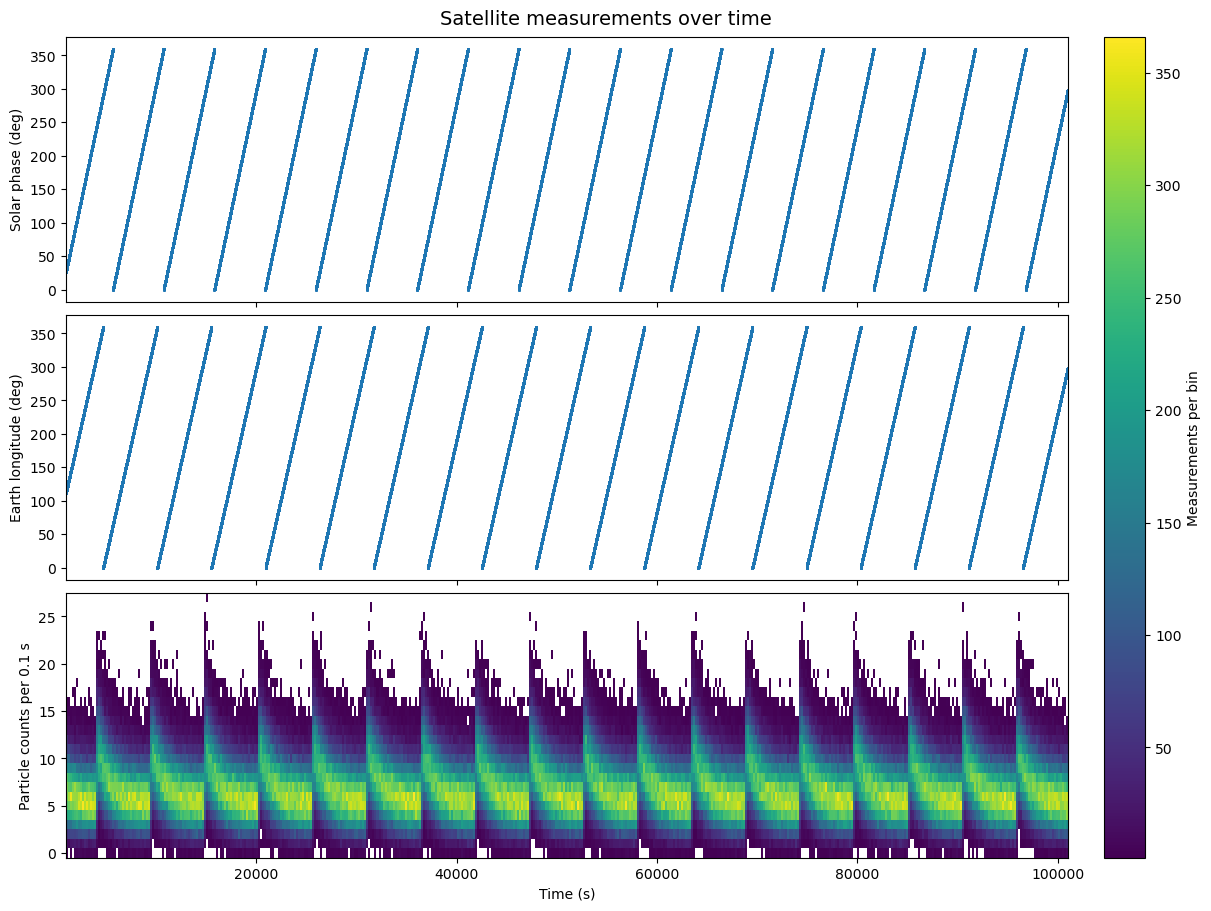

In [7]:
t = data[0] - data[0, 0]
solar_phase = data[1]
longitude = data[2]
particle_counts = data[3]

start = int(1e4)
num_points = int(1e6)
s = slice(start, start + num_points)

fig, ax = plt.subplots(
    3, 1, figsize=(12, 9), sharex=True,
    constrained_layout=True
)
fig.suptitle('Satellite measurements over time', fontsize=14)

# Scatter plots avoid connecting across angle wraparounds
ax[0].scatter(t[s], solar_phase[s], s=1, rasterized=True)
ax[0].set_ylabel('Solar phase (deg)')

ax[1].scatter(t[s], longitude[s], s=1, rasterized=True)
ax[1].set_ylabel('Earth longitude (deg)')

# 2D histogram for particle counts
h = ax[2].hist2d(
    t[s], particle_counts[s],
    bins=(500, np.arange(-0.5, particle_counts[s].max() + 1.5, 1)),
    cmap='viridis',
    cmin=1
)
ax[2].set_ylabel('Particle counts per 0.1 s')
ax[2].set_xlabel('Time (s)')

# Reserve the same colorbar space for all panels to keep time axes aligned
fig.colorbar(h[3], ax=ax, label='Measurements per bin', pad=0.02)

plt.show()

We observe periodic behavior in the solar phase, Earth longitude, and particle counts. In particular, the particle counts show recurring regions of enhanced activity, suggesting that the background may depend on the satellite's orbital position.

Now let's now take a closer look at the background cosmic rays.

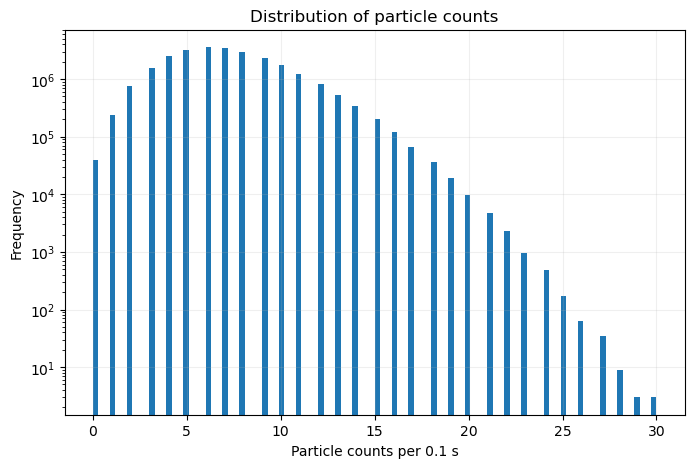

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(particle_counts, bins=100, log=True)

ax.set_xlabel('Particle counts per 0.1 s')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of particle counts')
ax.grid(alpha=0.2)

plt.show()

The histogram of particle counts has a single peak around 6 counts per 0.1 s, with a long tail toward higher counts. The largest observed count is 30, which appears as an isolated spike in the time series. This could indicate signal contamination, but it could also be a background fluctuation.

Since the background appears to vary with time, we model the particle counts using a Poisson distribution with a time-dependent mean $\lambda(t)$:

$$
P(N=k\mid t)
=
\frac{\lambda(t)^k e^{-\lambda(t)}}{k!}.
$$

We expect $\lambda(t)$ to be varying periodically over time.

## Section 2

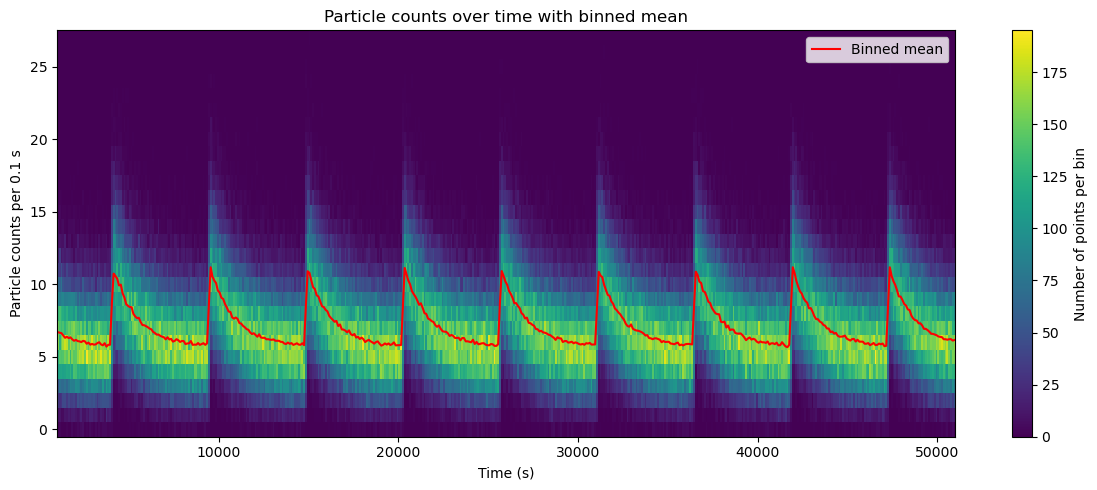

In [9]:
# Particle counts with binned mean
start = int(1e4)
num_points = int(5e5)
s = slice(start, start + num_points)

time_edges = np.linspace(t[s].min(), t[s].max(), 501)
value_edges = np.arange(-0.5, particle_counts[s].max() + 1.5, 1)

counts, time_edges, value_edges = np.histogram2d(
    t[s], particle_counts[s],
    bins=(time_edges, value_edges)
)

time_centers = (time_edges[:-1] + time_edges[1:]) / 2
value_centers = (value_edges[:-1] + value_edges[1:]) / 2

mean_counts = np.divide(
    counts @ value_centers,
    counts.sum(axis=1),
    out=np.full(len(time_centers), np.nan),
    where=counts.sum(axis=1) > 0
)

plt.figure(figsize=(12, 5))
plt.hist2d(t[s], particle_counts[s],
           bins=(time_edges, value_edges), cmap='viridis')
plt.colorbar(label='Number of points per bin')
plt.plot(time_centers, mean_counts, 'r-', label='Binned mean')
plt.xlabel('Time (s)')
plt.ylabel('Particle counts per 0.1 s')
plt.title('Particle counts over time with binned mean')
plt.legend()
plt.tight_layout()
plt.show()

The background shows a clear periodic pattern, repeating roughly every 90 minutes, which matches the satellite's orbital period. The average particle count rises quickly from about 6 to 10.5, then slowly drops back down. This behavior resembles the exponential discharge of an RC circuit, so we propose a periodic exponential decay model:

$$
\lambda(t) = \lambda_0 + A e^{-[(t-t_0)\bmod T]/\tau}.
$$

## Section 3

All 25,920,001 measurements used.
480 repeated rises; initial T = 5400.000000 s, t0 = 4055.000 s


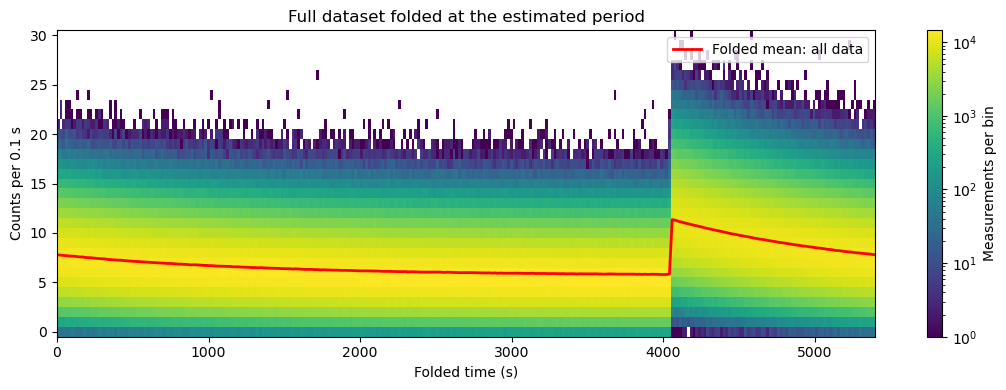

In [10]:
from scipy.signal import find_peaks
from scipy.optimize import least_squares
from scipy.stats import poisson, norm
from matplotlib.colors import LogNorm

t_full = data[0] - data[0, 0]
y_full = data[3]
bin_seconds = 10.0
n_bins = int(t_full[-1] // bin_seconds) + 1
exposure = np.zeros(n_bins, dtype=np.int64)
count_sum = np.zeros(n_bins)
count_square_sum = np.zeros(n_bins)
for lo in range(0, len(t_full), 1000000):
    ts = t_full[lo:lo+1000000]
    ys = y_full[lo:lo+1000000]
    j = (ts // bin_seconds).astype(np.int64)
    exposure += np.bincount(j, minlength=n_bins)
    count_sum += np.bincount(j, weights=ys, minlength=n_bins)
    count_square_sum += np.bincount(j, weights=ys**2, minlength=n_bins)
time_mid = (np.arange(n_bins) + 0.5) * bin_seconds
observed_mean = count_sum / np.maximum(exposure, 1)

# Locate repeated rapid rises to estimate the folding period.
w = 6
smoothed = np.convolve(observed_mean, np.ones(w)/w, mode='same')
rise = smoothed[w:] - smoothed[:-w]
peaks, _ = find_peaks(rise, distance=400, prominence=1)
jumps = time_mid[peaks] + w*bin_seconds/2
jumps = jumps[(jumps > 200) & (jumps < t_full[-1]-200)]
cycle = np.rint((jumps-jumps[0]) / np.median(np.diff(jumps)))
T_initial, intercept = np.polyfit(cycle, jumps, 1)
t0_initial = intercept % T_initial
print(f'All {len(t_full):,} measurements used.')
print(f'{len(jumps)} repeated rises; initial T = {T_initial:.6f} s, t0 = {t0_initial:.3f} s')

fold_edges = np.linspace(0, T_initial, 301)
value_edges = np.arange(-0.5, y_full.max()+1.5, 1)
fold_hist = np.zeros((300, len(value_edges)-1))
for lo in range(0, len(t_full), 1000000):
    folded = t_full[lo:lo+1000000] % T_initial
    fold_hist += np.histogram2d(folded, y_full[lo:lo+1000000],
                               bins=(fold_edges, value_edges))[0]
fold_centers = (fold_edges[:-1]+fold_edges[1:])/2
fold_n = fold_hist.sum(axis=1)
fold_mean = (fold_hist @ np.arange(len(value_edges)-1)) / fold_n
fig, ax = plt.subplots(figsize=(11,4))
h = ax.pcolormesh(fold_edges, value_edges, np.ma.masked_equal(fold_hist.T,0),
                  norm=LogNorm(), cmap='viridis', shading='auto')
ax.plot(fold_centers, fold_mean, 'r-', lw=2, label='Folded mean: all data')
ax.set(xlabel='Folded time (s)', ylabel='Counts per 0.1 s', title='Full dataset folded at the estimated period')
ax.legend()
fig.colorbar(h, ax=ax, label='Measurements per bin')
plt.tight_layout()
plt.show()


Fit converged: True - `xtol` termination condition is satisfied.
lambda0 (counts/0.1 s): 5.698488
A (counts/0.1 s): 5.695003
tau (s): 1351.193812
T (s): 5399.999783
t0 (s): 4049.972063
Period = 89.999996 min
Poisson deviance / degrees of freedom = 1.0006
Individual-count Pearson dispersion = 1.00015 (Poisson expectation: 1)


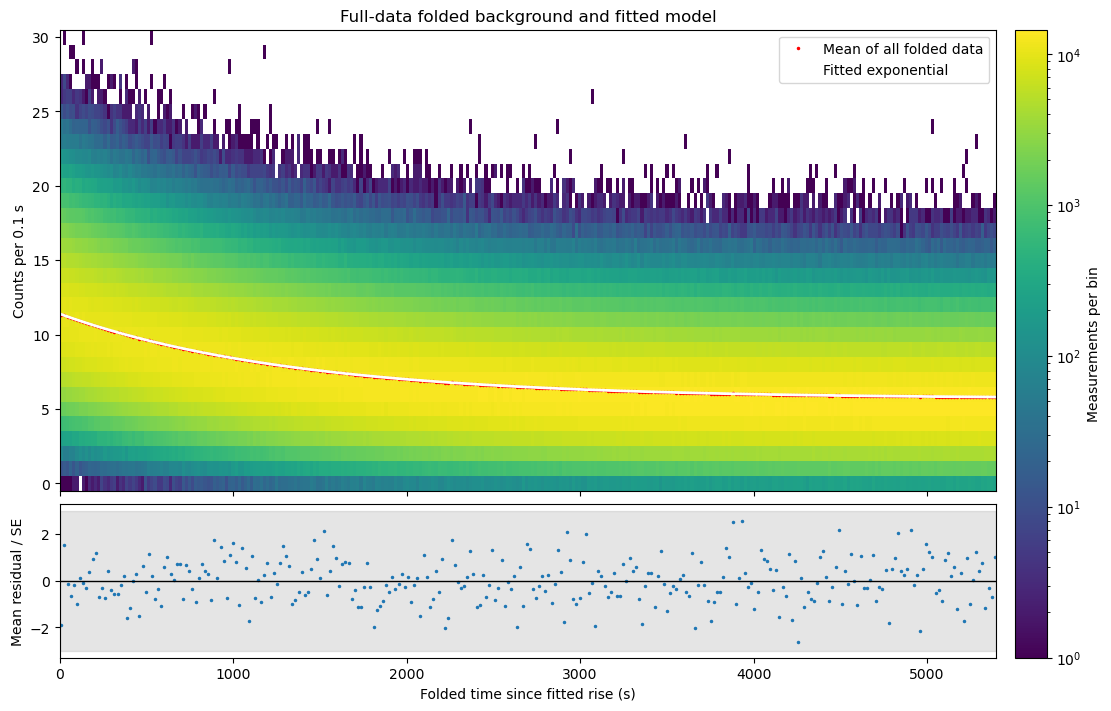

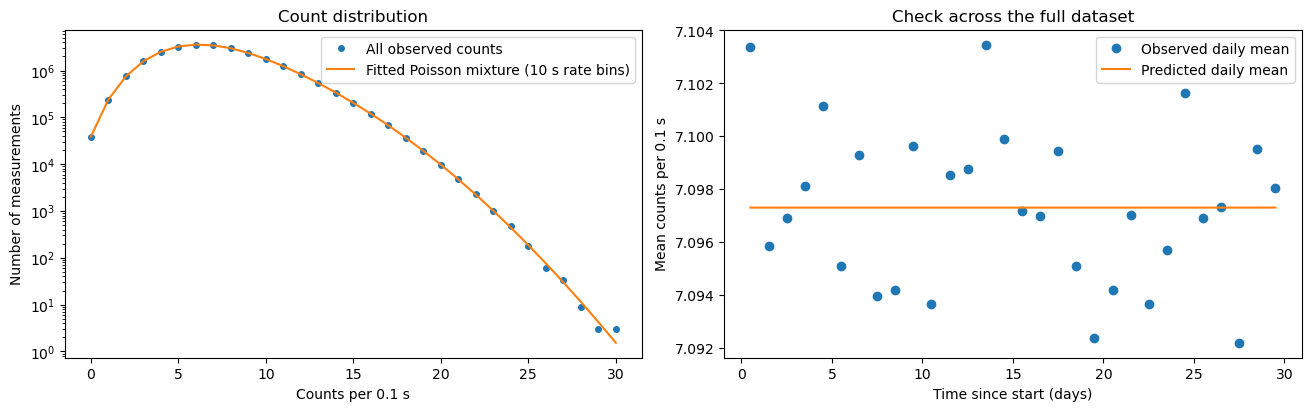

In [11]:
# Fit lambda(t) = lambda0 + A*exp(-((t-t0) % T)/tau).
# Every count contributes to 10 s totals; integrate the model over each bin.
# This binned Poisson likelihood approximates the changing rate within 10 s.
left = np.arange(n_bins)*bin_seconds - 0.05
right = np.minimum(left+bin_seconds, t_full[-1]+0.05)
fit_mask = exposure > 0

def background_model(time, lambda0, A, tau, T, t0):
    return lambda0 + A*np.exp(-((np.asarray(time)-t0) % T)/tau)

def bin_model(p):
    lambda0, A, tau, T, t0 = p
    def primitive(time):
        u = time-t0
        cycles = np.floor(u/T)
        phase = u % T
        return tau*(cycles*(-np.expm1(-T/tau)) - np.expm1(-phase/tau))
    return lambda0 + A*(primitive(right)-primitive(left))/(right-left)

def deviance_residual(p):
    expected = exposure[fit_mask]*bin_model(p)[fit_mask]
    observed = count_sum[fit_mask]
    term = expected-observed
    positive = observed > 0
    term[positive] += observed[positive]*np.log(observed[positive]/expected[positive])
    return np.sign(observed-expected)*np.sqrt(np.maximum(2*term, 0))

p0 = [6, 4.5, 1000, T_initial, t0_initial]
fit = least_squares(deviance_residual, p0,
                    bounds=([0.01,0.01,10,T_initial-2,t0_initial-120],
                            [20,30,20000,T_initial+2,t0_initial+120]),
                    x_scale=[6,4,1000,1,30], diff_step=[1e-5,1e-5,1e-5,1e-8,1e-7],
                    ftol=1e-9, xtol=1e-9, gtol=1e-7, max_nfev=120)
popt = fit.x
lambda0_fit, A_fit, tau_fit, T_fit, t0_fit = popt
print('Fit converged:', fit.success, '-', fit.message)
for name, value in zip(['lambda0 (counts/0.1 s)','A (counts/0.1 s)',
                        'tau (s)','T (s)','t0 (s)'], popt):
    print(f'{name}: {value:.6f}')
print(f'Period = {T_fit/60:.6f} min')
print(f'Poisson deviance / degrees of freedom = {np.sum(fit.fun**2)/(fit_mask.sum()-5):.4f}')

# Refold all measurements at the fitted period, aligning the rise to phase zero.
phase_edges = np.linspace(0,T_fit,301)
phase_hist = np.zeros_like(fold_hist)
phase_expected_sum = np.zeros(300)
pearson_sum = 0.0
for lo in range(0,len(t_full),1000000):
    ts = t_full[lo:lo+1000000]
    ys = y_full[lo:lo+1000000]
    phase = (ts-t0_fit) % T_fit
    lam = background_model(ts,*popt)
    phase_hist += np.histogram2d(phase,ys,bins=(phase_edges,value_edges))[0]
    j = np.minimum((phase/T_fit*300).astype(int),299)
    phase_expected_sum += np.bincount(j,weights=lam,minlength=300)
    pearson_sum += np.sum((ys-lam)**2/lam)
phase_n = phase_hist.sum(axis=1)
phase_centers = (phase_edges[:-1]+phase_edges[1:])/2
phase_mean = phase_hist @ np.arange(len(value_edges)-1) / phase_n
phase_predicted = phase_expected_sum/phase_n
phase_error = np.sqrt(phase_expected_sum)/phase_n
print(f'Individual-count Pearson dispersion = {pearson_sum/(len(t_full)-5):.5f} (Poisson expectation: 1)')

fig,axes = plt.subplots(2,1,figsize=(11,7),sharex=True,
                         gridspec_kw={'height_ratios':[3,1]},constrained_layout=True)
h = axes[0].pcolormesh(phase_edges,value_edges,np.ma.masked_equal(phase_hist.T,0),
                       norm=LogNorm(),cmap='viridis',shading='auto')
axes[0].plot(phase_centers,phase_mean,'r.',ms=3,label='Mean of all folded data')
grid = np.linspace(0,T_fit,1500,endpoint=False)
axes[0].plot(grid,lambda0_fit+A_fit*np.exp(-grid/tau_fit),'w-',lw=2,label='Fitted exponential')
axes[0].set(ylabel='Counts per 0.1 s',title='Full-data folded background and fitted model')
axes[0].legend()
fig.colorbar(h,ax=axes,label='Measurements per bin',pad=0.02)
axes[1].plot(phase_centers,(phase_mean-phase_predicted)/phase_error,'.',ms=3)
axes[1].axhline(0,color='k',lw=1)
axes[1].axhspan(-3,3,color='gray',alpha=0.2)
axes[1].set(xlabel='Folded time since fitted rise (s)',ylabel='Mean residual / SE')
plt.show()

# Compare the count distribution and the entire time span.
k = np.arange(len(value_edges)-1)
observed_hist = phase_hist.sum(axis=0)
expected_hist = np.zeros_like(k,dtype=float)
lam_bins = bin_model(popt)
for ki in k:
    expected_hist[ki] = np.sum(exposure*poisson.pmf(ki,lam_bins))
fig,axes = plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
axes[0].semilogy(k,observed_hist,'o',ms=4,label='All observed counts')
axes[0].semilogy(k,expected_hist,'-',label='Fitted Poisson mixture (10 s rate bins)')
axes[0].set(xlabel='Counts per 0.1 s',ylabel='Number of measurements',title='Count distribution')
axes[0].legend()
# Daily averages include every measurement and expose long-term model errors.
# Include the final endpoint in the last day, avoiding a one-sample extra day.
day_index = np.minimum((time_mid//86400).astype(int), int((t_full[-1]-0.05)//86400))
day_n = np.bincount(day_index,weights=exposure)
day_y = np.bincount(day_index,weights=count_sum)/day_n
day_model = np.bincount(day_index,weights=exposure*lam_bins)/day_n
axes[1].plot(np.arange(len(day_n))+0.5,day_y,'o',label='Observed daily mean')
axes[1].plot(np.arange(len(day_n))+0.5,day_model,'-',label='Predicted daily mean')
axes[1].set(xlabel='Time since start (days)',ylabel='Mean counts per 0.1 s',title='Check across the full dataset')
axes[1].legend()
plt.show()


Folding the full dataset at a period of 5400 s reveals a clear exponential decay. Fitting the model gives $\lambda_0 \approx 5.70$, $A \approx 5.70$, $\tau \approx 1351$ s, and $t_0 \approx 4050$ s. The fitted curve closely follows the folded mean, and the residuals fluctuate around zero. The deviance per degree of freedom is about 1.00, suggesting that the model describes the background well.

## Section 4

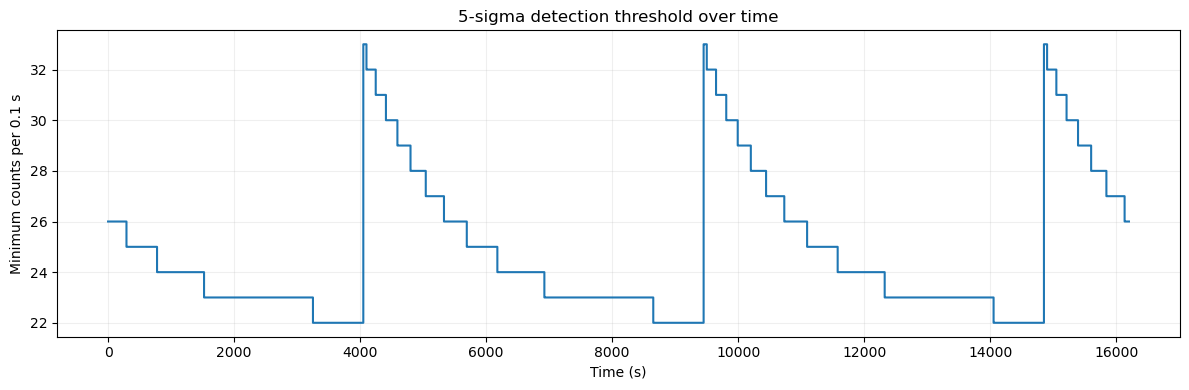

5-sigma threshold: 22 to 33 counts per 0.1 s


In [12]:
# Show three orbits so the changing threshold is visible.
t_plot = np.arange(0, 3 * T_fit, 1.0)
lambda_t = background_model(t_plot, *popt)
p_5sigma = norm.sf(5)

# Smallest n with P(N >= n) <= the one-sided 5-sigma probability.
threshold = poisson.isf(p_5sigma, lambda_t).astype(int) + 1
assert np.all(poisson.sf(threshold - 1, lambda_t) <= p_5sigma)
assert np.all(poisson.sf(threshold - 2, lambda_t) > p_5sigma)

plt.figure(figsize=(12, 4))
plt.step(t_plot, threshold, where='post')
plt.xlabel('Time (s)')
plt.ylabel('Minimum counts per 0.1 s')
plt.title('5-sigma detection threshold over time')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f'5-sigma threshold: {threshold.min()} to {threshold.max()} counts per 0.1 s')


The 5-sigma threshold varies from 22 to 33 counts per 0.1 s, repeating every 90 minutes. We use the Poisson upper tail with probability $P(N \ge n \mid \lambda(t)) \le 2.87\times10^{-7}$ for each individual measurement.

## Section 5

The periodic change in the background may be caused by the satellite's orbital motion. As it moves around Earth, it may pass through regions with different particle levels, causing the background to rise and fall each orbit. This could explain why the pattern repeats about every 90 minutes and motivates our periodic background model.